# Secado de leña de eucalipto en Talca: modelo 2D transiente de difusión de humedad
**IIQ2003 – Fenómenos de Transporte, 2026-2** · Proyecto semestral, Entrega 2

Modelo: difusión de humedad en un trozo cilíndrico (coordenadas *r*, *z*), con simetría angular y respecto del plano medio.

$$\frac{\partial M}{\partial t}=D_{ef}\left(\frac{\partial^2 M}{\partial r^2}+\frac1r\frac{\partial M}{\partial r}+\frac{\partial^2 M}{\partial z^2}\right),\quad 0<r<R,\;0<z<L/2$$

Condiciones: $M(r,z,0)=M_0$; $\partial_r M|_{r=0}=0$; $\partial_z M|_{z=L/2}=0$; $-D_{ef}\partial_r M|_{r=R}=h_m(M_{sup}-M_{eq})$; $D_{ef}\partial_z M|_{z=0}=h_m(M_{sup}-M_{eq})$.

**Objetivo:** tiempo $t^*$ para que la humedad promedio llegue a $M=0{,}25$ kg/kg (base seca, NCh 2907).

Las funciones del solver están en `modelo_secado.py`. Todo en unidades SI.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import modelo_secado as ms

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DIA = 86400.0   # [s/día]

## 1. Parámetros
**Los valores marcados con ⚠ son supuestos que el grupo debe verificar con una fuente antes de la entrega final.**

In [2]:
# --- Geometría del trozo (⚠ supuesto: leña típica; confirmar largo comercial) ---
R = 0.05          # radio del trozo [m]            (diámetro 10 cm)
L = 0.30          # largo del trozo [m]

# --- Madera: Eucalyptus globulus ---
D_ef = 3.0e-10    # difusividad efectiva [m2/s]. Rango 1,5-4,5e-10 medido en E. nitens (Biobío)
M0 = 0.80         # humedad inicial, base seca [kg/kg]  ⚠ confirmar para E. globulus verde
rho_s = 550.0     # densidad básica madera seca [kg/m3] ⚠ confirmar (solo se usa para estimar h_m)

# --- Aire (T y HR constantes por escenario) ---
# Verano: normal de enero Talca, T media = (30,9 + 12,1)/2. ⚠ HR de verano es supuesto (completar con boletín U. Talca)
# Invierno: normal de junio, T media = (13,3 + 5,1)/2; HR = promedio de 97,4 % (08:00) y 71,4 % (14:00) de junio 2025
ESCENARIOS = {
    "Verano (enero)":  dict(T=(30.9 + 12.1) / 2, HR=0.55),
    "Invierno (junio)": dict(T=(13.3 + 5.1) / 2, HR=0.844),
}
u_viento = 1.0    # velocidad del viento [m/s] ⚠ supuesto

# --- Objetivo ---
M_obj = 0.25      # humedad objetivo [kg/kg, base seca]

# --- Parámetros numéricos (se justifican en la sección 3) ---
Nr, Nz = 20, 60   # celdas en r y en z (mitad del largo)
dt = 3600.0       # paso de tiempo [s]
t_max = 600 * DIA # tiempo máximo simulado [s]

In [3]:
for nombre, e in ESCENARIOS.items():
    e["M_eq"] = ms.humedad_equilibrio(e["T"], e["HR"])
    e["h_m"] = ms.h_masa_efectivo(e["T"], e["HR"], u_viento, 2 * R, rho_s)
    e["Bi"] = e["h_m"] * R / D_ef
    print(f"{nombre:17s} T={e['T']:5.1f} °C  HR={e['HR']*100:4.1f} %  "
          f"M_eq={e['M_eq']*100:5.1f} %  h_m={e['h_m']:.2e} m/s  Bi_m={e['Bi']:.0f}")

Verano (enero)    T= 21.5 °C  HR=55.0 %  M_eq= 10.0 %  h_m=2.01e-06 m/s  Bi_m=335
Invierno (junio)  T=  9.2 °C  HR=84.4 %  M_eq= 18.1 %  h_m=3.74e-07 m/s  Bi_m=62


`h_m` se estima con una correlación de Sherwood (Churchill–Bernstein) y se convierte a base $M$ usando la pendiente de la isoterma. Con $Bi_m \gg 1$ la resistencia del aire es pequeña frente a la difusión interna, pero no es nula: en la sensibilidad (sección 5) reducir $h_m$ diez veces alarga $t^*$ cerca de un 10 %.

> Nota: en una conversación previa se estimó $Bi_m\sim10^5$–$10^6$ al usar el coeficiente del aire sin convertirlo a base $M$. El valor correcto, ya convertido, es el calculado arriba (del orden de cientos).

## 2. Validación contra solución analítica
Para $D_{ef}$ constante, $M_0$ uniforme y condición de borde convectiva, existe solución exacta: producto de la solución del cilindro infinito y de una placa de semiespesor $L/2$. Se compara la humedad promedio del trozo, caso verano.

t* numérico  = 17.03 días
t* analítico = 16.97 días  (diferencia 0.31 %)
Error máximo en M_prom = 0.0137 kg/kg (a t = 0.0 d)
Error en el rango M_prom < 0,5 kg/kg = 0.00152 kg/kg


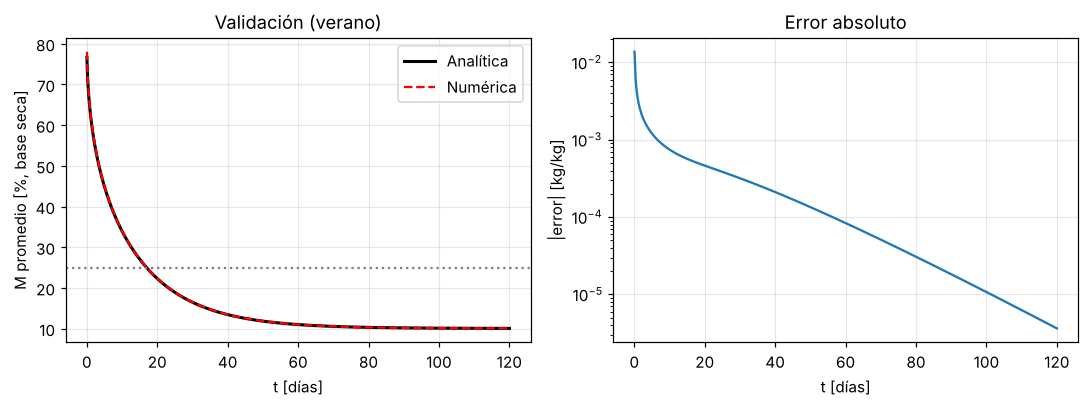

In [4]:
e = ESCENARIOS["Verano (enero)"]
res = ms.resolver(R, L, D_ef, e["h_m"], M0, e["M_eq"], Nr, Nz, dt, 120 * DIA)
t = res["t"][1:]
M_ana = ms.analitica_M_prom(t, R, L, D_ef, e["h_m"], M0, e["M_eq"])
err = np.abs(res["M_prom"][1:] - M_ana)

# t* analítico (curva decreciente: interpolación invertida)
t_ana = np.interp(M_obj, M_ana[::-1], t[::-1])
print(f"t* numérico  = {res['t_prom']/DIA:.2f} días")
print(f"t* analítico = {t_ana/DIA:.2f} días  (diferencia {abs(res['t_prom']-t_ana)/t_ana*100:.2f} %)")
print(f"Error máximo en M_prom = {err.max():.4f} kg/kg (a t = {t[err.argmax()]/DIA:.1f} d)")
print(f"Error en el rango M_prom < 0,5 kg/kg = {err[res['M_prom'][1:] < 0.5].max():.5f} kg/kg")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(t / DIA, M_ana * 100, "k-", lw=2, label="Analítica")
ax[0].plot(t / DIA, res["M_prom"][1:] * 100, "r--", lw=1.5, label="Numérica")
ax[0].axhline(25, color="gray", ls=":"); ax[0].set(xlabel="t [días]", ylabel="M promedio [%, base seca]", title="Validación (verano)")
ax[0].legend()
ax[1].semilogy(t / DIA, err); ax[1].set(xlabel="t [días]", ylabel="|error| [kg/kg]", title="Error absoluto")
plt.tight_layout(); plt.savefig("figures/validacion.png"); plt.show()

El error máximo ocurre al inicio, cuando el perfil tiene un gradiente muy fuerte en la superficie que una malla de 2,5 mm resuelve con menos precisión. El criterio que importa para el objetivo (el cruce de 25 %) coincide con la analítica.

## 3. Independencia de grilla y de paso de tiempo
Se refina la malla manteniendo celdas cuadradas ($\Delta r=\Delta z$, es decir $N_z=3N_r$) y se compara $t^*$.

  Nr   Nz  dr[mm]  t*_prom[d]  t*_centro[d]  dif. vs fina [%]
   5   15   10.00       17.46         34.07              2.66
  10   30    5.00       17.11         33.88              0.62
  20   60    2.50       17.03         33.83              0.12
  40  120    1.25       17.00         33.82              0.00


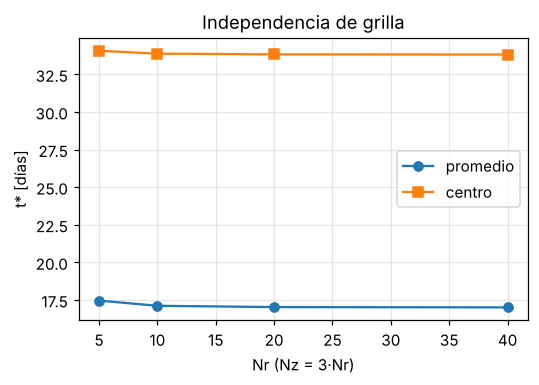

In [5]:
e = ESCENARIOS["Verano (enero)"]
filas = []
for n in [5, 10, 20, 40]:
    r = ms.resolver(R, L, D_ef, e["h_m"], M0, e["M_eq"], n, 3 * n, dt, 150 * DIA)
    filas.append((n, 3 * n, R / n * 1000, r["t_prom"] / DIA, r["t_centro"] / DIA))
ref = filas[-1][3]
print(f"{'Nr':>4} {'Nz':>4} {'dr[mm]':>7} {'t*_prom[d]':>11} {'t*_centro[d]':>13} {'dif. vs fina [%]':>17}")
for n, nz, dr_, tp, tc in filas:
    print(f"{n:4d} {nz:4d} {dr_:7.2f} {tp:11.2f} {tc:13.2f} {abs(tp-ref)/ref*100:17.2f}")

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot([f[0] for f in filas], [f[3] for f in filas], "o-", label="promedio")
ax.plot([f[0] for f in filas], [f[4] for f in filas], "s-", label="centro")
ax.set(xlabel="Nr (Nz = 3·Nr)", ylabel="t* [días]", title="Independencia de grilla"); ax.legend()
plt.tight_layout(); plt.savefig("figures/grilla.png"); plt.show()

In [6]:
# Independencia del paso de tiempo (malla Nr=20, Nz=60)
print(f"{'dt [s]':>8} {'t*_prom [d]':>12}")
for dt_ in [7200, 3600, 1800, 900]:
    r = ms.resolver(R, L, D_ef, e["h_m"], M0, e["M_eq"], 20, 60, float(dt_), 150 * DIA)
    print(f"{dt_:8d} {r['t_prom']/DIA:12.2f}")

  dt [s]  t*_prom [d]


    7200        17.05


    3600        17.03


    1800        17.01


     900        17.01


**Elección:** $N_r=20$, $N_z=60$, $\Delta t=3600$ s. Revisar la tabla: se mantiene esta malla si la diferencia con la malla fina es pequeña (el criterio, por ejemplo < 1 %, lo define el grupo y debe declararse en el informe).

## 4. Resultados: verano vs. invierno

Verano (enero)    M_eq = 10.0 %  t*(promedio) = 17 días   t*(centro) = 34 días


Invierno (junio)  M_eq = 18.1 %  t*(promedio) = 28 días   t*(centro) = 46 días


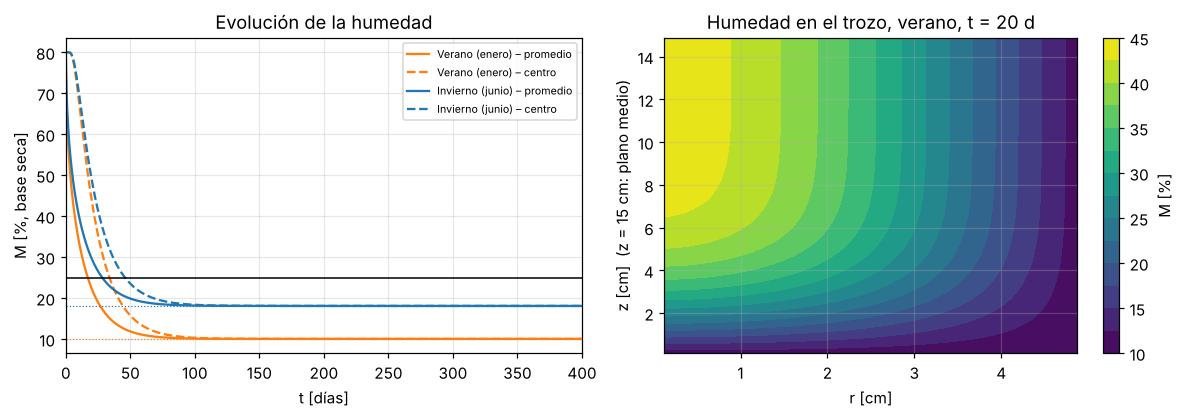

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
resumen = {}
for (nombre, e), col in zip(ESCENARIOS.items(), ["tab:orange", "tab:blue"]):
    r = ms.resolver(R, L, D_ef, e["h_m"], M0, e["M_eq"], Nr, Nz, dt, t_max, guardar_cada=int(10 * DIA / dt))
    resumen[nombre] = r
    ax[0].plot(r["t"] / DIA, r["M_prom"] * 100, color=col, label=f"{nombre} – promedio")
    ax[0].plot(r["t"] / DIA, r["M_centro"] * 100, color=col, ls="--", label=f"{nombre} – centro")
    ax[0].axhline(e["M_eq"] * 100, color=col, ls=":", lw=0.8)
    f = lambda x: "no se alcanza" if np.isnan(x) else f"{x/DIA:.0f} días"
    print(f"{nombre:17s} M_eq = {e['M_eq']*100:.1f} %  t*(promedio) = {f(r['t_prom'])}   t*(centro) = {f(r['t_centro'])}")
ax[0].axhline(25, color="k", ls="-", lw=1); ax[0].set(xlim=(0, 400), xlabel="t [días]", ylabel="M [%, base seca]", title="Evolución de la humedad")
ax[0].legend(fontsize=7)

# Perfil espacial de humedad a 60 días, verano
r = resumen["Verano (enero)"]
k = sorted(r["snaps"])[1]   # t = 20 días
RR, ZZ = np.meshgrid(r["rc"] * 100, r["zc"] * 100, indexing="ij")
cs = ax[1].contourf(RR, ZZ, r["snaps"][k] * 100, 15, cmap="viridis")
plt.colorbar(cs, ax=ax[1], label="M [%]"); ax[1].set(xlabel="r [cm]", ylabel="z [cm]  (z = 15 cm: plano medio)", title=f"Humedad en el trozo, verano, t = {k/DIA:.0f} d")
plt.tight_layout(); plt.savefig("figures/resultados.png"); plt.show()

## 5. Sensibilidad
$D_{ef}$ es el parámetro más incierto (rango medido 1,5–4,5×10⁻¹⁰ m²/s). También se varía el diámetro del trozo y $h_m$ (para comprobar que la condición de borde elegida es adecuada).

In [8]:
e = ESCENARIOS["Verano (enero)"]
casos = [("D_ef = 1,5e-10", dict(D=1.5e-10)), ("D_ef = 3,0e-10 (base)", dict(D=3.0e-10)),
         ("D_ef = 4,5e-10", dict(D=4.5e-10)),
         ("Diámetro 6 cm (R=3 cm)", dict(R_=0.03)), ("Diámetro 14 cm (R=7 cm)", dict(R_=0.07)),
         ("h_m x 0,1", dict(hf=0.1)), ("h_m x 10", dict(hf=10.0))]
print(f"{'Caso':26s} {'t*_prom [d]':>12} {'t*_centro [d]':>14}")
for nombre, p in casos:
    r = ms.resolver(p.get("R_", R), L, p.get("D", D_ef), e["h_m"] * p.get("hf", 1.0), M0, e["M_eq"],
                    Nr, 3 * Nr if "R_" in p else Nz, dt, 600 * DIA)
    print(f"{nombre:26s} {r['t_prom']/DIA:12.1f} {r['t_centro']/DIA:14.1f}")

Caso                        t*_prom [d]  t*_centro [d]


D_ef = 1,5e-10                     33.8           67.4


D_ef = 3,0e-10 (base)              17.0           33.8


D_ef = 4,5e-10                     11.4           22.6


Diámetro 6 cm (R=3 cm)              6.6           12.3


Diámetro 14 cm (R=7 cm)            31.0           65.5


h_m x 0,1                          18.8           35.6


h_m x 10                           16.8           33.6


## 6. Conclusiones
Completar con los números obtenidos arriba:
- Tiempo de secado hasta 25 % en verano vs. invierno, y qué implica para planificar el secado antes del invierno.
- Si en invierno el aire permite o no llegar al 25 % ($M_{eq}$ vs. 25 %).
- Qué tanto cambia $t^*$ con $D_{ef}$ y con el diámetro (sensibilidad).
- Limitaciones: $D_{ef}$ constante e isótropo, aire a T y HR constantes, sin radiación ni lluvia, $\rho_s$ y propiedades homogéneas.
